# PHASE 4 : MACHINE LEARNING MODEL

In [6]:
# Import the prerequisits
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df = pd.read_csv(r"C:\Users\Aditya\OneDrive\Documents\Intershala Data\Pyhton\Deep Learning\Data Cleaning\Books_cleaned_dataset.csv")
df.head()

,Title,Genre,Price,Price_Band,Rating,Rating_Percent,Title_Length
0,It's Only the Himalayas,Travel,45.17,High,2,40.0,23
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,Travel,49.43,High,4,80.0,64
2,See America: A Celebration of Our National Par...,Travel,48.87,High,3,60.0,66
3,Vagabonding: An Uncommon Guide to the Art of L...,Travel,36.94,Medium,2,40.0,67
4,Under the Tuscan Sun,Travel,37.33,Medium,3,60.0,20


In [14]:
# Feature and Target Selection
x = df[['Genre', 'Rating', 'Title_Length']]
y = df['Price']

In [16]:
# Categorical Encoding
x_encoded = pd.get_dummies(x, columns = ['Genre'], drop_first= True)

In [18]:
# Train-Test Split
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size= 0.2, random_state= 42)

In [20]:
# Training of Regression Model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [22]:
# Prediction
y_pred = model.predict(x_test)

In [24]:
# Model Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [30]:
# Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)
print('Mean Absolute Error:', mae)

Mean Absolute Error: 12.580858038339864


In [32]:
# Root Mean Squared Error
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 15.007265817814641


In [34]:
# R² Score
r2 = r2_score(y_test, y_pred)
print('R² Score:',r2)

R² Score: -0.0939837414649094


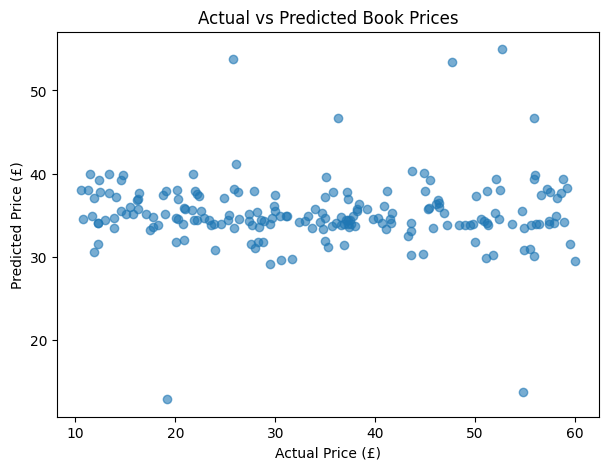

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.title("Actual vs Predicted Book Prices")
plt.show()

The regression model achieved a negative R² score, indicating that the selected features do not sufficiently explain price variability. This result aligns with earlier exploratory analysis, which showed weak correlations between price and other attributes. Hence, book pricing appears to be influenced by factors not captured in the dataset.

Model performance could potentially be improved by incorporating additional features such as author popularity, publisher reputation, or review text sentiment

### Conclusion:
    Model performance could potentially be improved by incorporating additional features such as author popularity, publisher reputation, or review text sentiment